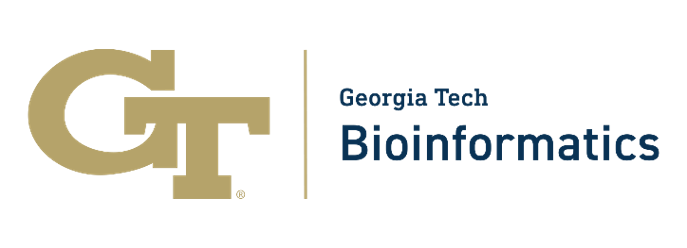

<div class="alert alert-block alert-info">
    <h1>BIOL 4150/BIOL 6150</h1>
    <h3>Instructor: Dr. King Jordan</h3>
    <p>Nilavrah Sensarma (nsensarma3@gatech.edu)</p>
    <p>Valli Sree Lasya Pasumarthy (vpasumarthy3@gatech.edu)

</p>
</div>

<div class="alert alert-block alert-warning">
    <h2>Project 7 (Polygenic Risk Scores) starter notebook</h2>
    <h3>Deadline: 11:59PM, November 10th, 2025</h3>
</div>

# **1. Knowing your data**
### *Total Questions: 5*
### *Total Points:  3+3+3+3+3= 15*


---

<div class="alert alert-block alert-warning">
    <h3>1.1 Our Phenotype and Population of interest</h3>
    <p>What is our trait of interest? What continental population are we focusing on? Give the 3 letter code for the population</p>
</div>

Our trait of interest is T2D, the population is UK Britain, so the 3 letter code will be EUR.

<div class="alert alert-block alert-warning">
    <h3>1.2 How many samples does your target data have? </h3>
<p> You can use bash commands or any tools you want.</div>

This is the total number of individuals in our pheno.tsv file.

In [13]:
!echo $(( $(wc -l < ~/biol6150/Data2/PRS/pheno.tsv) - 1 ))

96760


<div class="alert alert-block alert-warning">
    <h3>1.3 How many variants does chromosome 16 have?</h3>
    <p>Use a bash command or any tool of your choice.</p>
</div>

This is the total count of variants found on chromosome 16 in our gwas_summary_stats.tsv.

In [3]:
!awk '$1 == "16" {count++} END {print count+0}' ~/biol6150/Data2/PRS/gwas_summary_stats.tsv

28960


<div class="alert alert-block alert-warning">
    <h3>1.4 What is the 9th column in the GWAS summary statistics file?</h3>
    <p>what do you think it corresponds to?</p>
</div>

In [1]:
!head ~/biol6150/Data2/PRS/gwas_summary_stats.tsv

#CHROM	POS	ID	REF	ALT	PROVISIONAL_REF?	A1	OMITTED	A1_FREQ	FIRTH?	TEST	OBS_CT	OR	LOG(OR)_SE	Z_STAT	P	ERRCODE
1	723307	1:723307	G	C	Y	G	C	0.0367765	N	ADD	6254	1.0988	0.156739	0.601145	0.547743	.
1	727841	1:727841	A	G	Y	A	G	0.0542186	N	ADD	52150	0.934402	0.0551404	-1.23046	0.218524	.
1	729632	1:729632	T	C	Y	T	C	0.0371304	N	ADD	55359	1.06453	0.0610642	1.02406	0.305809	.
1	752721	1:752721	G	A	Y	A	G	0.158954	N	ADD	57674	1.01207	0.0318384	0.376923	0.706231	.
1	754105	1:754105	T	C	Y	T	C	0.037163	N	ADD	57934	1.05431	0.0597664	0.884839	0.376243	.
1	756604	1:756604	G	A	Y	A	G	0.13187	N	ADD	57864	1.00764	0.0334066	0.2279	0.819724	.
1	759036	1:759036	A	G	Y	A	G	0.0357288	N	ADD	56607	1.07217	0.0610519	1.14145	0.253681	.
1	761147	1:761147	C	T	Y	T	C	0.140896	N	ADD	55399	1.01286	0.0334429	0.382094	0.702392	.
1	767096	1:767096	G	A	Y	G	A	0.000509631	N	ADD	57885	0.888335	0.524267	-0.22585	0.821318	.


The 9th column of the gwas summary statistics is A1_FREQ


A1_FREQ is the frequency of the A1(the effect allele) allele in our dataset. For instance, the first line the A1 allele is G, so the frequency of A1 is ~3.7%.

<div class="alert alert-block alert-warning">
    <h3>1.5 Study your phenotype file </h3>
    <p> What are the number of cases and controls present in the overall cohort?</p>
</div>

In [14]:
!head ~/biol6150/Data2/PRS/pheno.tsv

FID	IID	T2D
BRIT00001	BRIT00001	1
BRIT00002	BRIT00002	1
BRIT00003	BRIT00003	1
BRIT00004	BRIT00004	1
BRIT00005	BRIT00005	1
BRIT00006	BRIT00006	1
BRIT00007	BRIT00007	1
BRIT00008	BRIT00008	1
BRIT00009	BRIT00009	1


In [15]:
#Write your cases and controls here. Why are they 1/2 instead of the typical 0/1 convention? 
!awk '$3 == "1" {count++} END {print count+0}' ~/biol6150/Data2/PRS/pheno.tsv #Controls
!awk '$3 == "2" {count++} END {print count+0}' ~/biol6150/Data2/PRS/pheno.tsv #Cases

89562
7198


These use the 1/2 convention with 1 being unaffected and 2 being affected. 0 or -9 are reserved for missing phenotypes. Apparently this is a historical convention that comes from older genomic software.

# **2. PRSice-2**
### *Total Questions: 3*
### *Total Points: 12+6+12 = 30*


---

<div class="alert alert-block alert-warning">
    <h3>2.1 Rerun PRSice-2 on the target data provided for this project.</h3>
    <p> Include bar-plot flags in the command. </p>
</div>

In [1]:
%%bash
Rscript ~/scratch/prs/PRSice.R \
--prsice ~/scratch/prs/PRSice_linux \
--base ~/biol6150/Data2/PRS/gwas_summary_stats.tsv \
--snp ID \
--chr '\#CHROM' \
--bp POS \
--a1 A1 \
--a2 REF \
--stat OR \
--or \
--pvalue P \
--target ~/biol6150/Data2/PRS/merged_geno \
--pheno ~/biol6150/Data2/PRS/pheno.tsv \
--pheno-col T2D \
--binary-target T \
--num-auto 22 \
--bar-levels 0.001,0.05,0.1,0.2,0.3,0.4,0.5,1 \
--fastscore \
--out ~/biol6150/SharedEnvironment/group4/PRS/test_results 

Trying to install ggplot2 in ./lib
Trying to install data.table in ./lib
Trying to install optparse in ./lib


PRSice 2.3.5 (2021-09-20) 
https://github.com/choishingwan/PRSice
(C) 2016-2020 Shing Wan (Sam) Choi and Paul F. O'Reilly
GNU General Public License v3
If you use PRSice in any published work, please cite:
Choi SW, O'Reilly PF.
PRSice-2: Polygenic Risk Score Software for Biobank-Scale Data.
GigaScience 8, no. 7 (July 1, 2019)
2026-11-16 19:37:22
/home/hice1/cechcharef3/scratch/prs/PRSice_linux \
    --a1 A1 \
    --a2 REF \
    --bar-levels 0.001,0.05,0.1,0.2,0.3,0.4,0.5,1 \
    --base /home/hice1/cechcharef3/biol6150/Data2/PRS/gwas_summary_stats.tsv \
    --binary-target T \
    --bp POS \
    --chr #CHROM \
    --clump-kb 250kb \
    --clump-p 1.000000 \
    --clump-r2 0.100000 \
    --fastscore  \
    --num-auto 22 \
    --or  \
    --out /home/hice1/cechcharef3/biol6150/SharedEnvironment/group4/PRS/test_results \
    --pheno /home/hice1/cechcharef3/biol6150/Data2/PRS/pheno.tsv \
    --pheno-col T2D \
    --pvalue P \
    --seed 723404322 \
    --snp ID \
    --stat OR \
    --targe

Begin plotting
Current Rscript version = 2.3.3
Plotting Bar Plot


<div class="alert alert-block alert-warning">
    <h3>2.2 Learn more about the outputs </h3>
    <p> <b>2.2.1</b> PRSice tells us "There are 1 region(s) with p-value less than 1e-5." in the output cell. What do you think this means? </p>
    <p> <b>2.2.2</b> Explain each of the output files PRSice gives us after a successful run. Which file has the PRS values? </p>
    <p> <b>2.2.3</b> What does the 3rd column in your .best file mean? </p>
    
</div>

In [10]:
#All your answers go here. 1-3 lines for each. Write each one in a different cell.

2.2.1: What this means is that after accounting for linkage disequilibrium, there is only 1 region that exceeds our p-value threshold.This is a fairly low number of results meaning that we are likely going to have lower predictive power in our PRS.

2.2.2: We have a test_results.best which are the PRS scores for every individual in our cohort using the p-value threshold. The .summary file is a summary file of our model's performance across every p-value threshold tested during the clumping process. The test_results.best is what contains the PRS scores shown below:

In [17]:
!head ~/biol6150/SharedEnvironment/group4/PRS/test_results.best

FID IID In_Regression PRS
BRIT00003 BRIT00003 Yes -0.000209114208
BRIT00008 BRIT00008 Yes 0.000317578998
BRIT00011 BRIT00011 Yes 2.0629093e-05
BRIT00015 BRIT00015 Yes -0.000162212218
BRIT00018 BRIT00018 Yes -0.000116142917
BRIT00019 BRIT00019 Yes -0.000359911193
BRIT00020 BRIT00020 Yes -0.000209384437
BRIT00021 BRIT00021 Yes -0.000236706282
BRIT00024 BRIT00024 Yes 0.000446188071


2.2.3: The third column In_Regression is whether or not this individual was included in the final regression model. An individual might be removed if they are missing phenotype data, or are low quality.

<div class="alert alert-block alert-warning">
    <h3>2.3 Bar Plot</h3>
    <p> <b>2.3.1</b> What does each bar in the bar plot mean? What is being thresholded here?</p>
    <p> <b>2.3.2</b> Write the p-value threshold and R² values at which your model achieves the best association </p>
    <p> <b>2.3.3</b> How would adding covariates change the best p-value threshold? </p> 
    <p> <b> 2.3.4</b> If the bars are of the same height, what could it mean? </p>
</div>

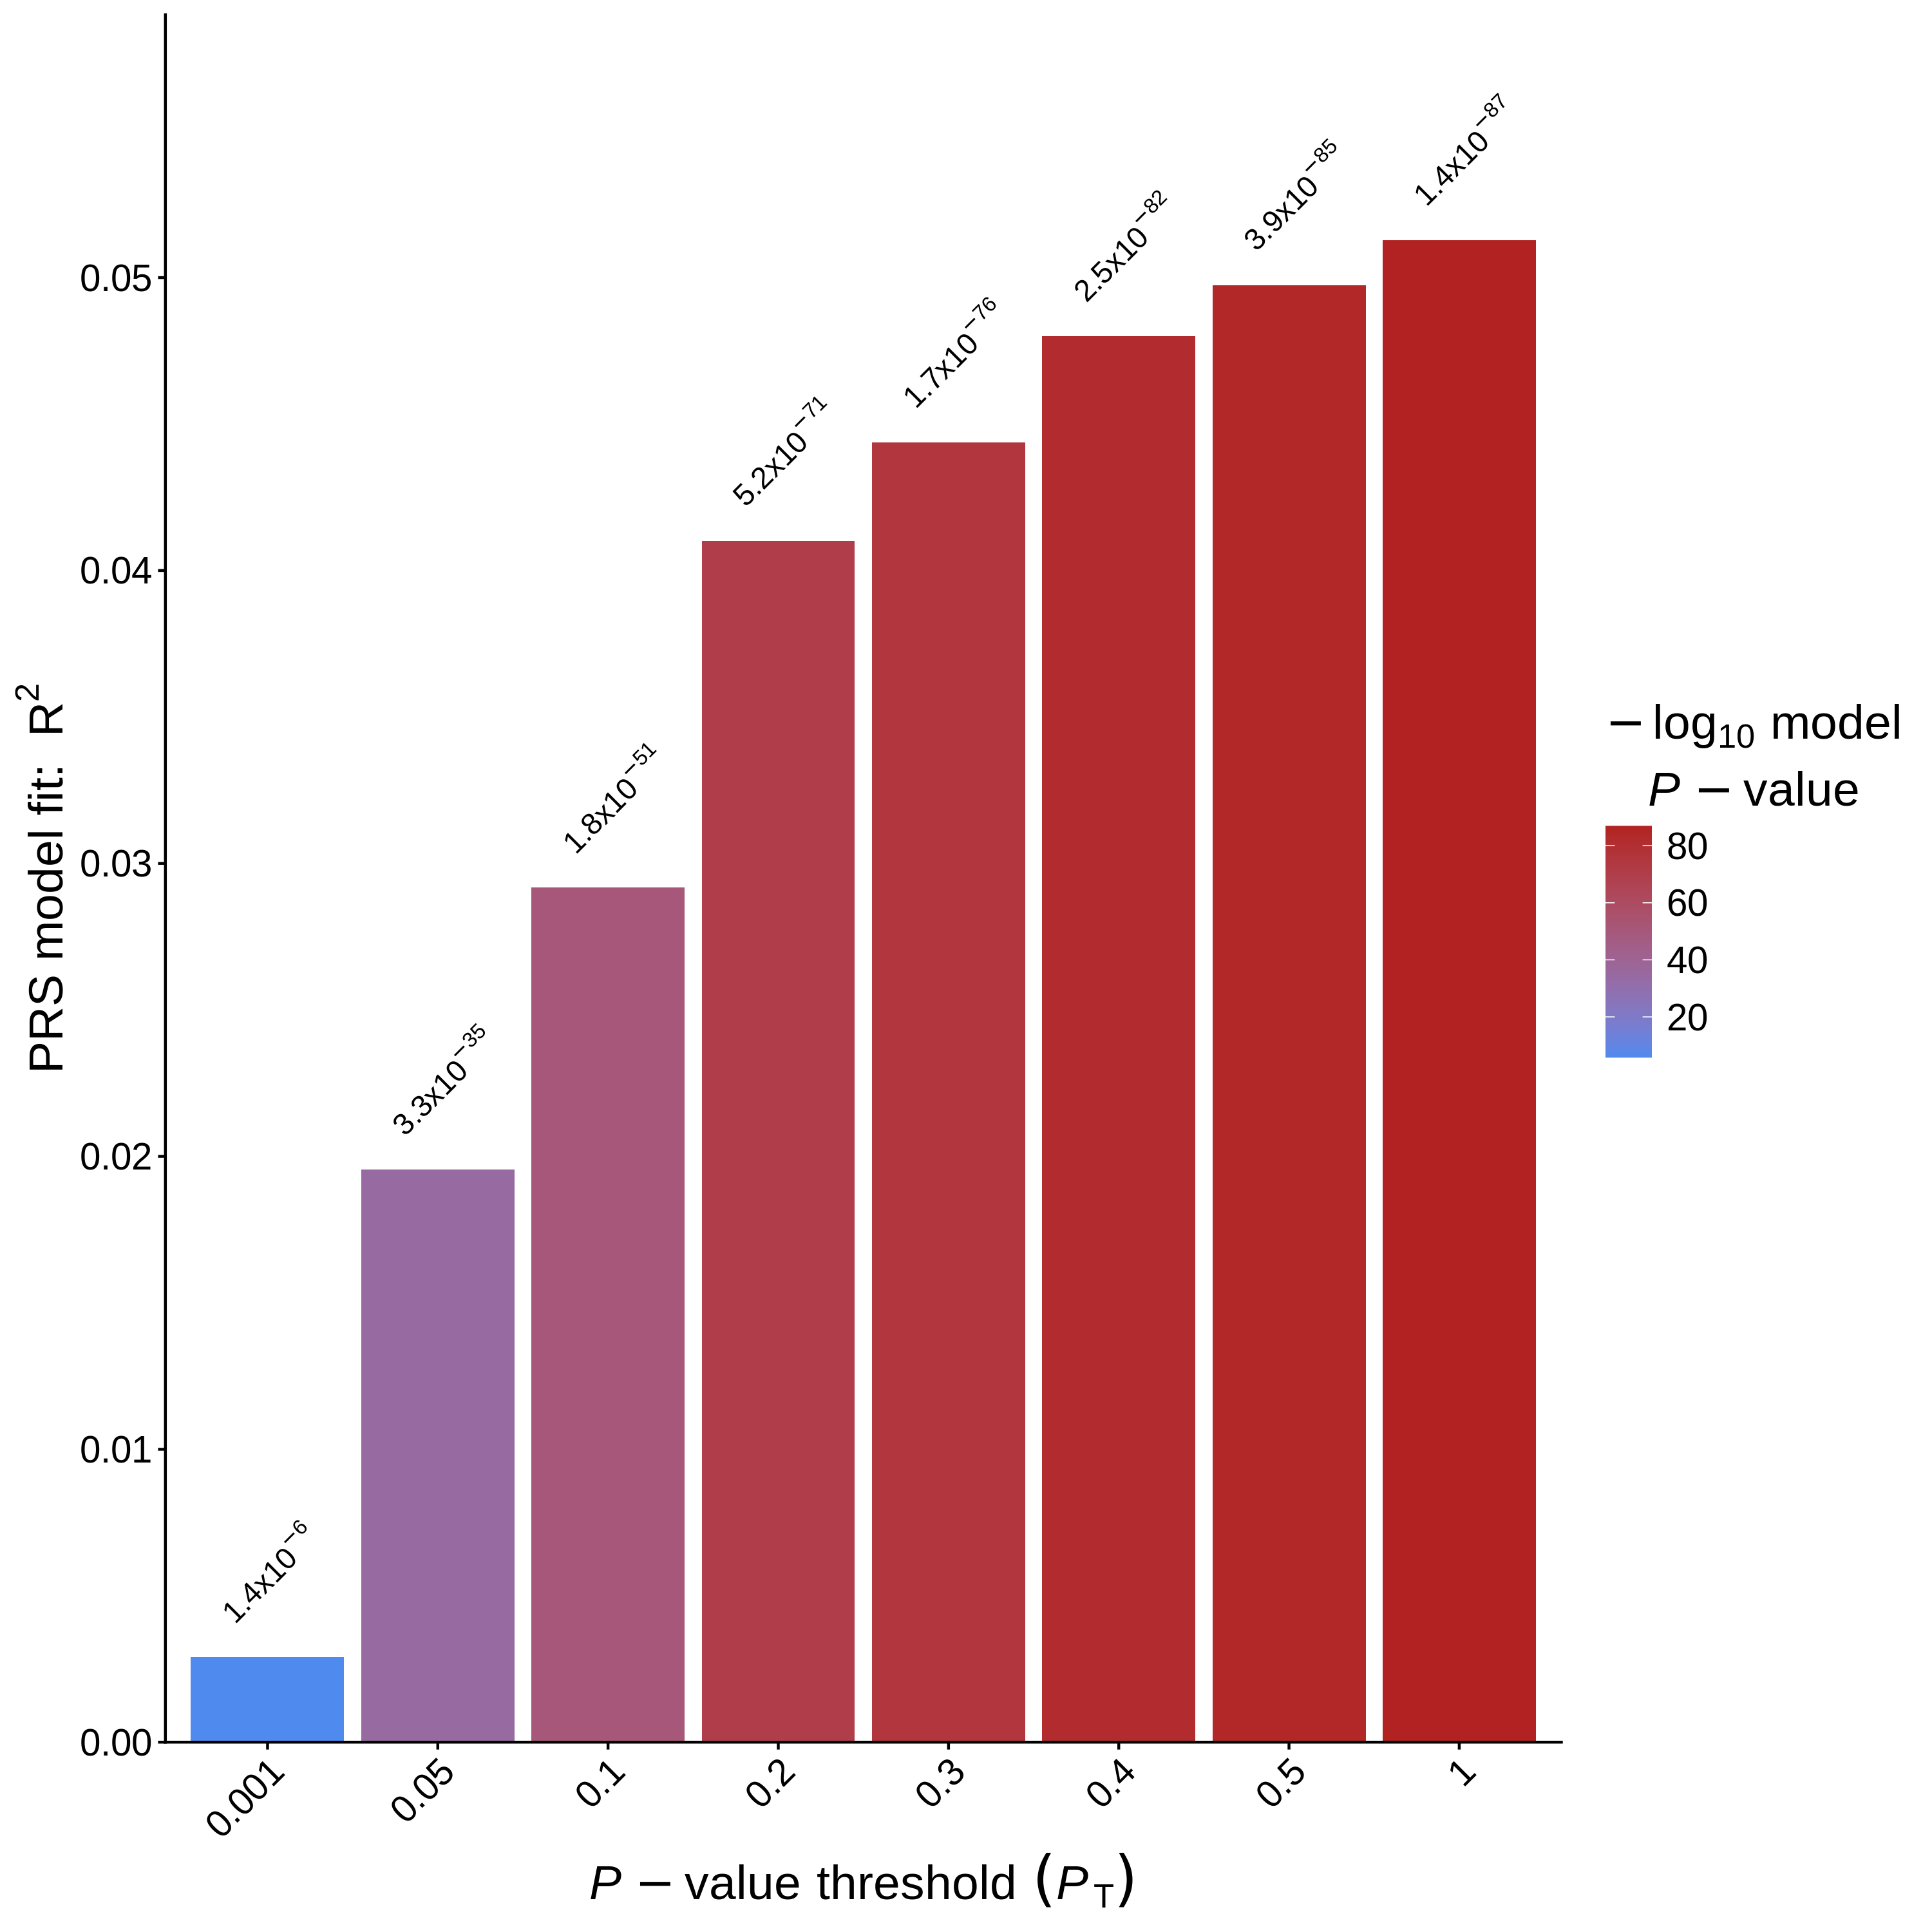

#### 2.3.1

Each bar represents the R² value (model fit) of the polygenic risk score (PRS) at a specific GWAS p-value threshold. Each bar shows how well a risk score predicts T2D. The score is built using only the SNPs whose GWAS p-value is at or below the number under the bar. A taller bar means a better prediction (higher R²). The color and the number above the bar show how strong the link between the score and T2D is. 
What is being thresholded is the GWAS p-value of the SNPs: a small cutoff like 0.001 uses only a few strong SNPs, and 1 uses all of them.

#### 2.3.2

The best threshold is p ≤ 1(all 3,305 SNPs). R² is 0.0513, equivalent to 5.1%, and the p-value is 1.4 × 10⁻⁸⁷. The bars keep getting taller as more SNPs are added. This is common for T2D, which is influenced by many genes that each have a small effect.


#### 2.3.3

Covariates (like age, sex, and ancestry) explain some of T2D on their own. PRSice only counts what the score adds on top of them, so the R² values would get smaller. The best threshold might move to a stricter cutoff if part of the signal came from those covariates. If the signal is truly genetic, as it seems here, the best threshold would probably stay about the same.


#### 2.3.4

If the bars are the same height, the extra SNPs added between those thresholds do not improve prediction. The possible reasons are that no new SNPs enter the score between those levels, for example because of clumping or the small variant overlap, the added SNPs are noise with effects near zero, the score has saturated and more SNPs add nothing, or the model has little power, so all bars are near zero.

# **3. pgsc_calc**
### *Total Questions: 3*
### *Total Points: 12+6+12= 30*


---

<div class="alert alert-block alert-warning">
    <h3>3.1 Rerun pgsc_calc on the target data provided for this project.</h3>
    <p> Create a samplesheet for this pgsc_calc run. Use PGS002308 for the statistics file.</p>
</div>

In [ ]:
#Write your commands here for building your samplesheet. You can name it anything.

In [ ]:
%%bash

echo "sampleset,path_prefix,chrom,format" > samplesheet.csv
echo "t2d,$HOME/biol6150/Data2/PRS/merged_geno,,bfile" >> samplesheet.csv
cat samplesheet.csv

sampleset,path_prefix,chrom,format
t2d,/home/hice1/rshahrivar3/biol6150/Data2/PRS/merged_geno,,bfile


In [ ]:
#Your command to run pgsc_calc here

In [8]:
%%bash

nextflow run pgscatalog/pgsc_calc \
  -profile conda \
  --input samplesheet.csv \
  --pgs_id PGS002308 \
  --target_build GRCh37 \
  --max_cpus 6 \
  --max_memory 16.GB \
  --min_overlap 0 \
  --outdir . \
  -resume


 N E X T F L O W   ~  version 26.10.6

Launching `https://github.com/pgscatalog/pgsc_calc` [focused_poisson] revision: 72ee54f211 [main]

WARN: Unrecognized config option 'channels'
WARN: ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
  There is a problem with your Conda configuration!

  You will need to set-up the conda-forge and bioconda channels correctly.
  Please refer to https://bioconda.github.io/
  The observed channel order is 
  [conda-forge, bioconda]
  but the following channel order is required:
  [conda-forge, bioconda, defaults]
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~




------------------------------------------------------
  pgscatalog/pgsc_calc v2.3.0-g72ee54f
------------------------------------------------------
Core Nextflow options
  revision   : main
  runName    : focused_poisson
  launchDir  : /home/hice1/rshahrivar3/BIOL-6150-Project7
  workDir    : /home/hice1/rshahrivar3/BIOL-6150-Project7/work
  projectDir : /home/hice1/rshahrivar3/.nextflow/assets/.repos/pgscatalog/pgsc_calc/clones/72ee54f2119d2fe65ac671327342dfc412bd0a3b
  userName   : rshahrivar3
  profile    : conda
  configFiles: 

!! Only displaying parameters that differ from the pipeline defaults !!
------------------------------------------------------
If you use pgscatalog/pgsc_calc for your analysis please cite:

* The Polygenic Score Catalog
  https://doi.org/10.1101/2024.05.29.24307783
  https://doi.org/10.1038/s41588-021-00783-5

* The nf-core framework
  https://doi.org/10.1038/s41587-020-0439-x

* Software dependencies
  https://github.com/pgscatalog/pgsc_calc/blob/main/

[-        ] PGS…SCCALC:DOWNLOAD_SCOREFILES -
[-        ] PGS…UT_CHECK:FORMAT_SCOREFILES -
[-        ] PGS…MPATIBLE:PLINK2_RELABELBIM -
[-        ] PGS…PATIBLE:PLINK2_RELABELPVAR -
[-        ] PGS…MAKE_COMPATIBLE:PLINK2_VCF -

[-        ] PGS…SCCALC:DOWNLOAD_SCOREFILES -
[-        ] PGS…UT_CHECK:FORMAT_SCOREFILES -
[-        ] PGS…MPATIBLE:PLINK2_RELABELBIM -
[-        ] PGS…PATIBLE:PLINK2_RELABELPVAR -
[-        ] PGS…MAKE_COMPATIBLE:PLINK2_VCF -
[-        ] PGS…CCALC:MATCH:MATCH_VARIANTS -
[-        ] PGS…SCCALC:MATCH:MATCH_COMBINE -
[-        ] PGS…C:APPLY_SCORE:PLINK2_SCORE -
[-        ] PGS…PPLY_SCORE:SCORE_AGGREGATE -
[-        ] PGS…SCCALC:REPORT:SCORE_REPORT -
[-        ] PGS…CCALC:DUMPSOFTWAREVERSIONS -

[6e/f3ba3b] PGS…308, pgp_id:, trait_efo:]) | 1 of 1, cached: 1 ✔
[-        ] PGS…UT_CHECK:FORMAT_SCOREFILES -
[skipped  ] PGS…ELBIM (t2d chromosome ALL) | 1 of 1, stored: 1 ✔
[-        ] PGS…PATIBLE:PLINK2_RELABELPVAR -
[-        ] PGS…MAKE_COMPATIBLE:PLINK2_VCF -
[-        ] P

<div class="alert alert-block alert-warning">
    <h3>3.2 Outputs</h3>
    <p> <b> 3.2.1</b> Paste a screenshot of the report.html generated that helps in understanding more about the relationship between our base and target datasets </p>
    <p> <b> 3.2.2</b> What is the match %? Why is it that?</p>
</div>

In [10]:
#All your answers here. Write each one in a different cell.

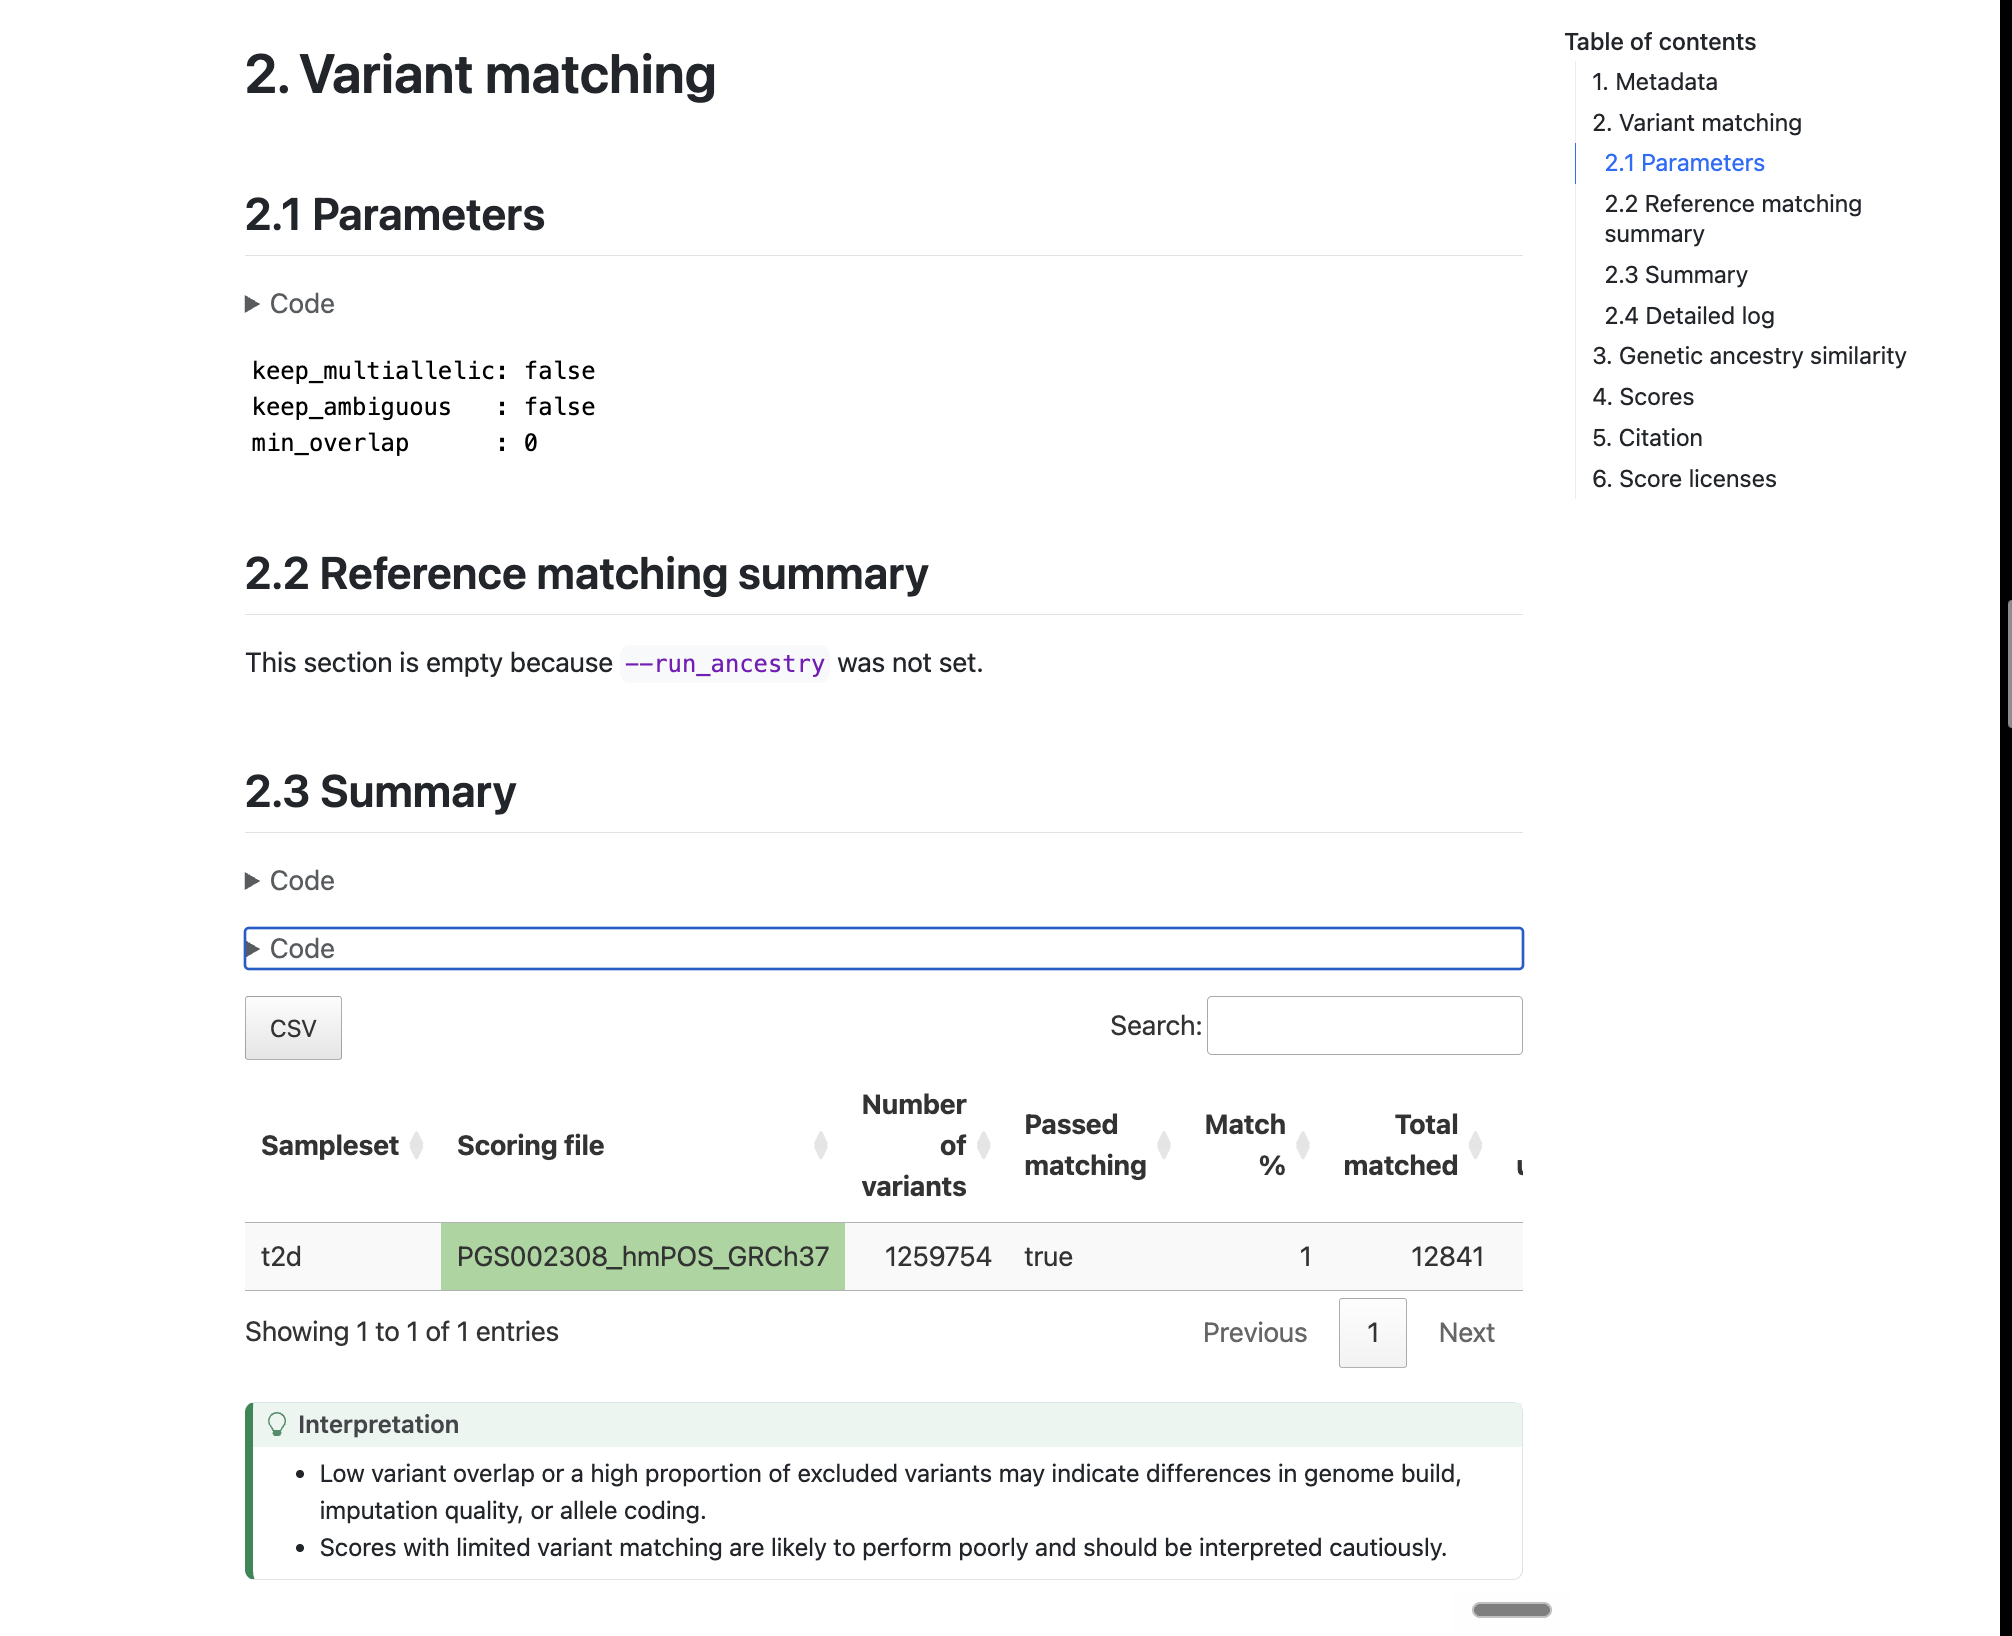

The match rate is only ~1% (12,841 of 1,259,754 variants). PGS002308 was built with PRS-CSx, which is a genome-wide Bayesian method that gives a weight to ~1.26 million variants across the genome. Our target data (merged_geno) contains far fewer variants, so most of the score's variants are not present in it. The genome build is not the cause, since both the score and our data are GRCh37. Because the match is below the default 75% threshold, we had to set --min_overlap 0 to compute the score. So The PRS is based on a small fraction of the original weights.

<div class="alert alert-block alert-warning">
    <h3>3.3 Choose a different PGS from PGS Catalog. Make sure it is relevant to the trait of interest.</h3>
    <p><b>3.3.1</b> Run pgsc_calc on the PGS ID you chose</p>
    <p> <b>3.3.2</b> Talk about why you selected this PGS file (1-3 lines)</p>
    <p> <b>3.3.3</b> Write the PGS and PGP website links for the selected file.</p>
    <p><b> 3.3.4 </b>  Can you find the train and test sizes used in the publication? What was the distribtion (by continental ancestry; eg: European, African, EastAsian, etc.) for the samples used in training?</p>
</div>

In [17]:
#Your code for 3.3.1 here

In [14]:
%%bash
nextflow run pgscatalog/pgsc_calc \
  -profile conda \
  --input samplesheet.csv \
  --pgs_id PGS000036 \
  --target_build GRCh37 \
  --max_cpus 6 \
  --max_memory 16.GB \
  --min_overlap 0 \
  --outdir pgs000036_results \
  -resume


 N E X T F L O W   ~  version 26.10.6

Launching `https://github.com/pgscatalog/pgsc_calc` [hungry_avogadro] revision: 72ee54f211 [main]

WARN: Unrecognized config option 'channels'
WARN: ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
  There is a problem with your Conda configuration!

  You will need to set-up the conda-forge and bioconda channels correctly.
  Please refer to https://bioconda.github.io/
  The observed channel order is 
  [conda-forge, bioconda]
  but the following channel order is required:
  [conda-forge, bioconda, defaults]
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~




------------------------------------------------------
  pgscatalog/pgsc_calc v2.3.0-g72ee54f
------------------------------------------------------
Core Nextflow options
  revision   : main
  runName    : hungry_avogadro
  launchDir  : /home/hice1/rshahrivar3/BIOL-6150-Project7
  workDir    : /home/hice1/rshahrivar3/BIOL-6150-Project7/work
  projectDir : /home/hice1/rshahrivar3/.nextflow/assets/.repos/pgscatalog/pgsc_calc/clones/72ee54f2119d2fe65ac671327342dfc412bd0a3b
  userName   : rshahrivar3
  profile    : conda
  configFiles: 

!! Only displaying parameters that differ from the pipeline defaults !!
------------------------------------------------------
If you use pgscatalog/pgsc_calc for your analysis please cite:

* The Polygenic Score Catalog
  https://doi.org/10.1101/2024.05.29.24307783
  https://doi.org/10.1038/s41588-021-00783-5

* The nf-core framework
  https://doi.org/10.1038/s41587-020-0439-x

* Software dependencies
  https://github.com/pgscatalog/pgsc_calc/blob/main/

[-        ] PGS…SCCALC:DOWNLOAD_SCOREFILES -

[-        ] PGS…SCCALC:DOWNLOAD_SCOREFILES -
[-        ] PGS…UT_CHECK:FORMAT_SCOREFILES -
[-        ] PGS…MPATIBLE:PLINK2_RELABELBIM -
[-        ] PGS…PATIBLE:PLINK2_RELABELPVAR -
[-        ] PGS…MAKE_COMPATIBLE:PLINK2_VCF -
[-        ] PGS…CCALC:MATCH:MATCH_VARIANTS -
[-        ] PGS…SCCALC:MATCH:MATCH_COMBINE -

[-        ] PGS…SCCALC:DOWNLOAD_SCOREFILES -
[-        ] PGS…UT_CHECK:FORMAT_SCOREFILES -
[-        ] PGS…MPATIBLE:PLINK2_RELABELBIM -
[-        ] PGS…PATIBLE:PLINK2_RELABELPVAR -
[-        ] PGS…MAKE_COMPATIBLE:PLINK2_VCF -
[-        ] PGS…CCALC:MATCH:MATCH_VARIANTS -
[-        ] PGS…SCCALC:MATCH:MATCH_COMBINE -
[-        ] PGS…C:APPLY_SCORE:PLINK2_SCORE -
[-        ] PGS…PPLY_SCORE:SCORE_AGGREGATE -
[-        ] PGS…SCCALC:REPORT:SCORE_REPORT -

[-        ] PGS…SCCALC:DOWNLOAD_SCOREFILES | 0 of 1
[-        ] PGS…UT_CHECK:FORMAT_SCOREFILES -
[skipped  ] PGS…ELBIM (t2d chromosome ALL) | 1 of 1, stored: 1 ✔
[-        ] PGS…PATIBLE:P

In [18]:
#All your answers here. Write each one in a different cell.

In [15]:
!ls pgs000036_results/t2d/score/

aggregated_scores.txt.gz  report.html  versions.yml


In [16]:
!zcat pgs000036_results/t2d/match/*summary*.csv* 2>/dev/null || cat pgs000036_results/t2d/match/*summary*.csv

dataset,accession,score_pass,match_status,ambiguous,is_multiallelic,duplicate_best_match,duplicate_ID,match_flipped,match_IDs,count,percent
t2d,PGS000036_hmPOS_GRCh37,true,unmatched,,,,,,,169097,98.7433503261333
t2d,PGS000036_hmPOS_GRCh37,true,matched,false,false,false,false,false,NA,2152,1.2566496738667088


3.3.2

So I chose the PGS000036  that was developed for type 2 diabetes and itwas trained in European ancestry UK Biobank participants, which matches our population as well (the UK, EUR, etc). It is also much smaller than PGS002308 (~171k vs ~1.26M variants), and its apparently built by pruning and thresholding, which is the the same approach as PRSice-2. So I expected a better variant match and a comparison with our PRSice-2 results but its just slightly higher, and the absolute number of matched vars is actually much smaller (2,152 vs 12,841). So this is because of the merged_geno that we have, it contains a small subset of the genome so no matter what we choose its gonna be a small match ratio. NOTE: there was a 75% threshold error that I ran into when running the pgsc from nextflow, I modfied the threshold.

The table comparison is basically:

PGS002308 vs PGS000036:

Vars in score, 1,259,754 vs 171,249
matched: 12,841 vs 2,152
match percentage: 1.02% vs 1.26%

3.3.3 links
- PGS: https://www.pgscatalog.org/score/PGS000036/
- PGP: https://www.pgscatalog.org/publication/PGP000023/

3.3.4 train/test sizes and ancestry
- GWAs: 455,313 individuals (55,005 cases, 400,308 controls), mostly European, plus African American, East Asian, Hispanic and South Asian samples.
- Training: 117,946 individuals (5,639 cases, 112,307 controls), 100% European, from UK Biobank.
- Testing in the original publication: 324,870 individuals (13,480 cases, 311,390 controls), European, from UK Biobank. AUROC was 0.66 for the score alone and 0.73 with covariates.

# **4. Visualisation & comparison**
### *Total Questions: 4*
### *Total Points: 10+10+3+2=25*


---

<div class="alert alert-block alert-warning">
    <h3>4.1 Generate risk gradient plots for PRSice-2 and pgsc_calc (PGS002308).</h3>
    <p> Try different number of bins. Choose a suitable number.</p>
    <p><b>4.1.1</b> Are the plots different for each tool? If yes, why do you think so?</p>
</div>

In [2]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

,prs_bin,n,cases,prev
0,0,1900,70,0.036842
1,1,1900,81,0.042632
2,2,1900,89,0.046842
3,3,1900,82,0.043158
4,4,1900,103,0.054211
5,5,1900,138,0.072632
6,6,1900,160,0.084211
7,7,1900,164,0.086316
8,8,1900,214,0.112632
9,9,1900,332,0.174737


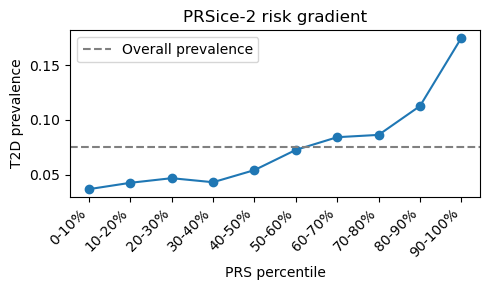

In [3]:
#Your code for PRSice risk gradient plot here
base  = Path.home() / "biol6150"
pheno = pd.read_csv(base / "Data2/PRS/pheno.tsv", sep="\t")
pheno = pheno[pheno["T2D"].isin([1, 2])].copy()
pheno["T2D_bin"] = pheno["T2D"].map({1: 0, 2: 1})        # 1/2 -> 0/1

df = pd.read_csv(base / "SharedEnvironment/group4/PRS/test_results.best", sep=r"\s+")
df = df[df["In_Regression"] == "Yes"]
df = df.merge(pheno[["FID", "IID", "T2D_bin"]], on=["FID", "IID"], how="inner")

df["prs_bin"] = pd.qcut(df["PRS"], 10, labels=False, duplicates="drop")

gradient = (
    df.groupby("prs_bin")
      .agg(n=("T2D_bin", "size"), cases=("T2D_bin", "sum"))
      .reset_index()
)
gradient["prev"] = gradient["cases"] / gradient["n"]
display(gradient)

plt.figure(figsize=(5, 3))
plt.plot(gradient["prs_bin"], gradient["prev"], marker="o")
plt.axhline(df["T2D_bin"].mean(), ls="--", color="gray", label="Overall prevalence")
plt.xticks(range(len(gradient)),
           [f"{int(b*10)}-{int(b*10)+10}%" for b in gradient["prs_bin"]],
           rotation=45, ha="right")
plt.ylabel("T2D prevalence")
plt.xlabel("PRS percentile")
plt.title("PRSice-2 risk gradient")
plt.legend()
plt.tight_layout()
plt.show()

                     


,prs_bin,n,cases,prev
0,0,1900,128,0.067368
1,1,1900,110,0.057895
2,2,1900,136,0.071579
3,3,1900,112,0.058947
4,4,1900,146,0.076842
5,5,1900,151,0.079474
6,6,1900,143,0.075263
7,7,1900,156,0.082105
8,8,1900,175,0.092105
9,9,1900,176,0.092632


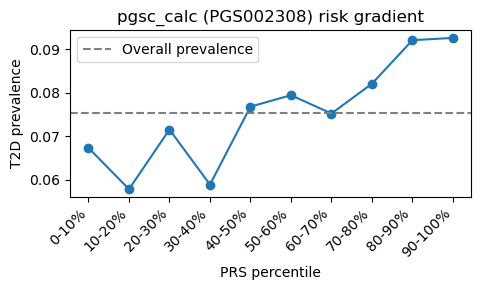

In [4]:
#Your code for pgsc_calc risk gradient plot here
base  = Path.home() / "biol6150"

df2 = pd.read_csv(
    base / "SharedEnvironment/group4/PRS/pgsc_results/t2d/score/aggregated_scores.txt.gz",
    sep="\t")

df2 = df2.merge(pheno[["IID", "T2D_bin"]], on="IID", how="inner")

df2["prs_bin"] = pd.qcut(df2["SUM"], 10, labels=False, duplicates="drop")

gradient2 = (
    df2.groupby("prs_bin")
       .agg(n=("T2D_bin", "size"), cases=("T2D_bin", "sum"))
       .reset_index()
)
gradient2["prev"] = gradient2["cases"] / gradient2["n"]
display(gradient2)

plt.figure(figsize=(5, 3))
plt.plot(gradient2["prs_bin"], gradient2["prev"], marker="o")
plt.axhline(df2["T2D_bin"].mean(), ls="--", color="gray", label="Overall prevalence")
plt.xticks(range(len(gradient2)),
           [f"{int(b*10)}-{int(b*10)+10}%" for b in gradient2["prs_bin"]],
           rotation=45, ha="right")
plt.ylabel("T2D prevalence")
plt.xlabel("PRS percentile")
plt.title("pgsc_calc (PGS002308) risk gradient")
plt.legend()
plt.tight_layout()
plt.show()

#### 4.1.1 Are the plots different?**

Yes. The PRSice-2 plot goes up clearly, from about 4% T2D in the lowest group to about 17% in the highest. The pgsc_calc plot goes up only a little, from about 7% to 9%, and it bounces up and down along the way.

#### Why?

- PRSice-2 builds its score from the same kind of people we are testing (UK Biobank), so the score fits them well.
- pgsc_calc uses a score made by a different study for many different ancestries, so it fits our people less well.
- Our genotype data has only about 63,000 variants, but the pgsc_calc score has about 1.26 million. Most of the score can't be used, which makes it weaker.
- PRSice-2 also picked its best settings using the same data it is tested on, which makes it look a bit better than it really is.

<div class="alert alert-block alert-warning">
    <h3>4.2 Calculate AUC values and generate AUC-ROC curves for PRSice-2 and pgsc_calc (PGS002308)</h3>
    <p><b>4.2.1</b> Which tool has more AUC value? Why do you think?</p>
    <p><b>4.2.2</b> How do AUC-ROC curves help us understand the performance of our models?</p> 
</div>

PRSice-2 AUC = 0.651


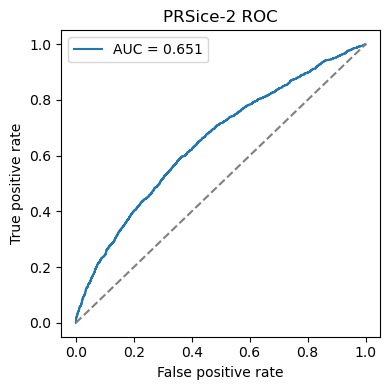

In [5]:
#Your code for PRsice AUC ROC Curve here. 
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import roc_curve, roc_auc_score

base = Path.home() / "biol6150"

pheno = pd.read_csv(base / "Data2/PRS/pheno.tsv", sep="\t")
pheno = pheno[pheno["T2D"].isin([1, 2])].copy()
pheno["T2D_bin"] = pheno["T2D"].map({1: 0, 2: 1})   # 1/2 -> 0/1

df = pd.read_csv(base / "SharedEnvironment/group4/PRS/test_results.best", sep=r"\s+")
df = df[df["In_Regression"] == "Yes"]
df = df.merge(pheno[["FID", "IID", "T2D_bin"]], on=["FID", "IID"], how="inner")

auc_prsice = roc_auc_score(df["T2D_bin"], df["PRS"])
fpr, tpr, _ = roc_curve(df["T2D_bin"], df["PRS"])
print(f"PRSice-2 AUC = {auc_prsice:.3f}")

plt.figure(figsize=(4, 4))
plt.plot(fpr, tpr, label=f"AUC = {auc_prsice:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("PRSice-2 ROC")
plt.legend()
plt.tight_layout()
plt.show()

pgsc_calc AUC = 0.541


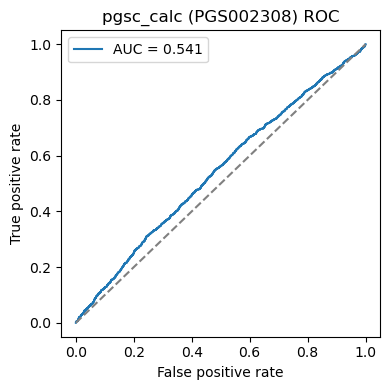

In [6]:
#Your code for pgsc_calc AUC ROC Curve here.
base = Path.home() / "biol6150"

df2 =  pd.read_csv(
    base / "SharedEnvironment/group4/PRS/pgsc_results/t2d/score/aggregated_scores.txt.gz",
    sep="\t")
df2 = df2.merge(pheno[["IID", "T2D_bin"]], on="IID", how="inner")

auc_pgsc = roc_auc_score(df2["T2D_bin"], df2["SUM"])
fpr2, tpr2, _ = roc_curve(df2["T2D_bin"], df2["SUM"])
print(f"pgsc_calc AUC = {auc_pgsc:.3f}")

plt.figure(figsize=(4, 4))
plt.plot(fpr2, tpr2, label=f"AUC = {auc_pgsc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("pgsc_calc (PGS002308) ROC")
plt.legend()
plt.tight_layout()
plt.show()

#### Write your answer for 4.2.1 here

PRSice-2 has the higher AUC (0.651 vs 0.541). The pgsc_calc curve sits almost on the diagonal line, so that score is only slightly better than random guessing. PRSice-2 builds its score from GWAS data of the same kind of people we are testing, so its weights fit this cohort well. It also picked its best settings using the same data, which makes it look a bit better. The pgsc_calc score (PGS002308) was made by a different study for many ancestries, and only a small part of its 1.26 million variants exist in our 63,000-variant data, so most of the score is missing and it predicts poorly.

#### Write your answer for 4.2.2 here

An ROC curve shows how well a score tells people with T2D apart from people without it. It plots the true positive rate against the false positive rate at every possible cutoff, so we don’t have to pick just one cutoff. The AUC turns the curve into one number: 0.5 means random guessing and 1.0 means perfect separation. The farther the curve bows above the diagonal line, the better the model. It also lets us compare different models on the same scale and isn’t thrown off by having far fewer cases than controls.

<div class="alert alert-block alert-warning">
    <h3>4.3 Explain the differences between PRSice-2 and pgsc_calc</h3>
    <p> The two tools, including plink2, can be used for calculating polygenic risk scores. How do each of them differ? </p>
</div>

PRSice-2 builds a risk score from scratch. You give it GWAS results (the base file), and it picks which SNPs to keep and tests many p-value cutoffs to find the one that predicts T2D best in your data. It needs the phenotype to do this, and it makes plots like the bar plot.

pgsc_calc doesn't build a score. It applies a score that someone else already published in the PGS Catalog, such as PGS002308. It fixes up the data first by matching genome builds, flipping alleles, and handling ambiguous SNPs. It then reports how many variants matched and makes a `report.html`. It can also compare ancestry and normalize scores. It runs as a Nextflow pipeline with containers, which makes it easy to reproduce.

plink2 is a general tool for genotype data. Its `--score` command just multiplies each person's alleles by the weights you give it and adds them up. It does no clumping, no thresholding, no matching, and no reports, so you have to prepare everything yourself.


<div class="alert alert-block alert-warning">
    <h3>4.4 Mention any errors you ran into when running the tools</h3>
    <p> On a scale of 1-10, how much did you rely on AI for this project? </p>
    <p> (1 = not at all, 10 = heavily dependent) </p>
</div>

#Paste the errors here. Briefly write how you fixed them
Faced an issue when trying to generate the bar plot and had to use Rscript ~/scratch/prs/PRSice.R \ for it to work

In [28]:
#Write your answer here
AI score 2 
used it to understand the difference between the different tools